# Retailrocket EDA

Вопрос: в каких категориях магазин недобирает покупки относительно среднего
и на каком этапе (до или после корзины) это происходит.
Результат: список приоритетных категорий для проверки.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [2]:
data_dir = Path("data")
events = pd.read_csv(data_dir / "events.csv")
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [3]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


## Базовая воронка

Сначала сравним просмотры, добавления в корзину и покупки среди уникальных посетителей. Это даст базовый ориентир, с которым потом можно будет сравнивать отдельные часы, категории и группы пользователей.

In [4]:
print("Уникальных посетителей всего:", events["visitorid"].nunique())

funnel = (
    events
    .groupby("event")
    .agg(
        events=("event", "size"),
        visitors=("visitorid", "nunique")
    )
    .reindex(["view", "addtocart", "transaction"])
)

funnel["share_of_viewers"] = (
    funnel["visitors"] / funnel.loc["view", "visitors"]
)

funnel

Уникальных посетителей всего: 1407580


,events,visitors,share_of_viewers
event,,,
view,2664312,1404179,1.000000
addtocart,69332,37722,0.026864
transaction,22457,11719,0.008346


In [5]:
viewers = set(events.loc[events["event"] == "view", "visitorid"])
carters = set(events.loc[events["event"] == "addtocart", "visitorid"])
buyers = set(events.loc[events["event"] == "transaction", "visitorid"])

print("посетителей без view:", events["visitorid"].nunique() - len(viewers))
print("покупателей без view:", len(buyers - viewers))
print("корзина среди viewers, %:", round(len(carters & viewers) / len(viewers) * 100, 2))
print("покупка среди viewers, %:", round(len(buyers & viewers) / len(viewers) * 100, 2))

посетителей без view: 3401
покупателей без view: 428
корзина среди viewers, %: 2.45
покупка среди viewers, %: 0.8


Посетителей без зафиксированного view 3401, из них 428 покупали: это особенности логирования, а не реальное поведение.
Среди посетителей с view в корзину добавляли 2,45%, покупали 0,8%. Это описательные доли, а не строгая воронка: в логе нет сессий.

## Показатели по часам

Проверим, меняется ли доля покупок в зависимости от часа суток. Если разница окажется устойчивой, её можно будет использовать как направление для дальнейшего анализа поведения пользователей.

In [6]:
events["event_time"] = pd.to_datetime(events["timestamp"], unit="ms")
events["hour"] = events["event_time"].dt.hour

hourly = (
    events
    .groupby(["hour", "event"])["visitorid"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=["view", "addtocart", "transaction"], fill_value=0)
)

hourly["purchase_rate"] = hourly["transaction"] / hourly["view"]
hourly

event,view,addtocart,transaction,purchase_rate
hour,,,,
0,89168,2283,682,0.007648
1,88570,2203,629,0.007102
2,92317,2181,660,0.007149
3,96192,2241,613,0.006373
4,93129,2216,585,0.006282
5,75495,1869,542,0.007179
6,49382,1232,359,0.007270
7,28347,652,189,0.006667
8,16842,346,79,0.004691


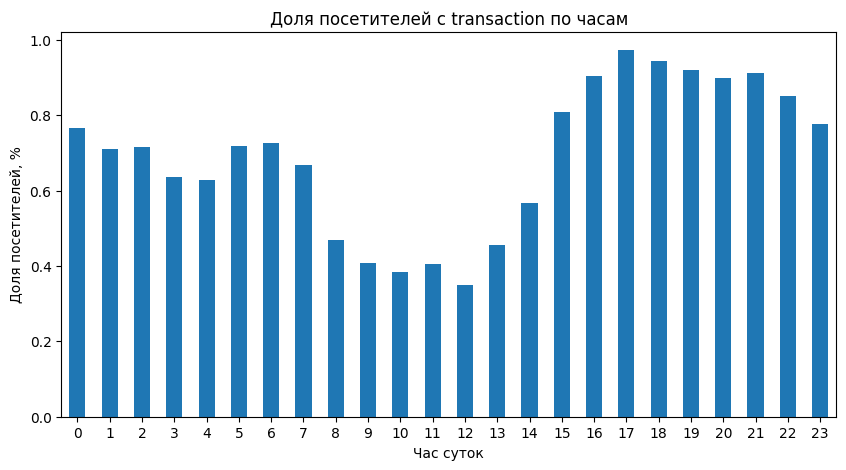

In [7]:
hourly["purchase_rate"].mul(100).plot(
    kind="bar",
    figsize=(10, 5),
    title="Доля посетителей с transaction по часам"
)

plt.xlabel("Час суток")
plt.ylabel("Доля посетителей, %")
plt.xticks(rotation=0)
plt.show()

Часы в UTC, часовой пояс магазина неизвестен. Доля покупок около 0,35-0,45% с 8 до 13 часов
и около 0,9% с 16 до 22. Ночью (0-7) много просмотров и доля 0,6-0,8%.
Это связь по времени, причину данные не показывают.

## Свойства товаров

Чтобы сравнивать поведение по категориям, нужно связать события с характеристиками товаров. Сначала посмотрим, какие свойства доступны и какие из них имеют понятный смысл.

In [8]:
properties_part1 = pd.read_csv(data_dir / "item_properties_part1.csv")
properties_part1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999999 entries, 0 to 10999998
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   timestamp  int64 
 1   itemid     int64 
 2   property   object
 3   value      object
dtypes: int64(2), object(2)
memory usage: 335.7+ MB


In [9]:
print(properties_part1["property"].value_counts().to_string())

property
888           1629817
790            970800
available      817387
categoryid     426305
6              343207
283            323681
776            311654
678            261829
364            256340
202            242984
839            226921
159            226502
917            226437
764            226242
112            226102
227            188209
698            157281
451            142388
663            131331
962            128976
400            118416
689            116244
28              93598
928             87128
1036            79306
810             77540
544             62450
348             61416
713             56559
1032            44011
19              41218
566             39614
581             36959
978             34777
981             33873
720             30199
960             29602
243             29445
38              29413
46              29310
434             29117
71              28424
797             27865
591             27420
961             27000
4

In [10]:
properties_part2 = pd.read_csv(data_dir / "item_properties_part2.csv")

cats = pd.concat(
    [p[p["property"] == "categoryid"] for p in (properties_part1, properties_part2)],
    ignore_index=True,
)
item_category = (
    cats.sort_values("timestamp")
    .drop_duplicates("itemid", keep="last")
    .rename(columns={"value": "categoryid"})[["itemid", "categoryid"]]
)

events_with_category = events.merge(item_category, on="itemid", how="left")

print(events_with_category["categoryid"].isna().sum(), "событий без категории")
print("строк не изменилось:", len(events) == len(events_with_category))

255585 событий без категории
строк не изменилось: True


In [11]:
no_cat = events_with_category["categoryid"].isna()
no_cat.groupby(events_with_category["event"]).mean().round(3)

event
addtocart      0.012
transaction    0.021
view           0.095
Name: categoryid, dtype: float64

In [12]:
category_metrics = (
    events_with_category
    .dropna(subset=["categoryid"])
    .groupby(["categoryid", "event"])
    .size()
    .unstack(fill_value=0)
)

category_metrics.head()

event,addtocart,transaction,view
categoryid,,,
0,59,12,1049
1,392,80,5847
10,0,0,2
100,0,0,18
1000,0,0,27


## Светофор категорий

Сравниваем конверсию каждой категории со средней по магазину.
Красные покупают значимо хуже среднего, зеленые лучше, желтые на уровне среднего.

In [13]:
cm = category_metrics[["view", "addtocart", "transaction"]].copy()

overall_rate = cm["transaction"].sum() / cm["view"].sum()

cm["purchase_rate"] = cm["transaction"] / cm["view"]
cm["view_share"] = cm["view"] / cm["view"].sum()
cm["expected_tx"] = cm["view"] * overall_rate
cm["gap_tx"] = cm["expected_tx"] - cm["transaction"]
cm["z"] = (cm["transaction"] - cm["expected_tx"]) / np.sqrt(cm["expected_tx"])
cm["tier"] = np.select([cm["z"] <= -2, cm["z"] >= 2], ["red", "green"], default="yellow")

cm = cm.sort_values("view", ascending=False)
cm["cum_view_share"] = cm["view_share"].cumsum()

cm["tier"].value_counts()

tier
yellow    750
green     176
red       160
Name: count, dtype: int64

In [14]:
tiers = cm.groupby("tier").agg(
    categories=("view", "size"),
    views=("view", "sum"),
    purchases=("transaction", "sum"),
)
tiers["views_%"] = (tiers["views"] / tiers["views"].sum() * 100).round(1)
print(tiers)

for share in (0.5, 0.8, 0.9):
    n = (cm["cum_view_share"] <= share).sum() + 1
    print(f"{int(share * 100)}% просмотров дают {n} категорий из {len(cm)}")


        categories    views  purchases  views_%
tier                                           
green          176   611448      10839     25.4
red            160  1082223       4965     44.9
yellow         750   716364       6178     29.7
50% просмотров дают 69 категорий из 1086
80% просмотров дают 227 категорий из 1086
90% просмотров дают 346 категорий из 1086


## Приоритетные категории

Берем красные категории с наибольшим недобором покупок и смотрим, на каком этапе они проседают.

In [15]:
cm["rate_ratio"] = cm["purchase_rate"] / overall_rate
cm["cart_rate"] = cm["addtocart"] / cm["view"]
cm["buy_per_cart"] = cm["transaction"] / cm["addtocart"]

cart_avg = cm["addtocart"].sum() / cm["view"].sum()
buy_avg = cm["transaction"].sum() / cm["addtocart"].sum()

red = cm[cm["tier"] == "red"].sort_values("gap_tx", ascending=False).head(15).copy()
red["weak_stage"] = np.where(
    red["cart_rate"] / cart_avg < red["buy_per_cart"] / buy_avg,
    "до корзины",
    "после корзины",
)

red[["view", "transaction", "gap_tx", "rate_ratio", "cart_rate", "buy_per_cart", "weak_stage"]].round(3)

event,view,transaction,gap_tx,rate_ratio,cart_rate,buy_per_cart,weak_stage
categoryid,,,,,,,
491,59300,263,277.877,0.486,0.026,0.170,после корзины
1279,33532,123,182.846,0.402,0.022,0.169,после корзины
1051,73016,485,180.981,0.728,0.023,0.283,до корзины
646,27669,87,165.370,0.345,0.017,0.180,после корзины
683,37765,211,133.456,0.613,0.024,0.232,после корзины
342,45288,281,132.073,0.680,0.028,0.219,после корзины
333,22382,84,120.147,0.411,0.019,0.202,после корзины
1477,13370,14,107.948,0.115,0.014,0.074,после корзины
499,13441,16,106.596,0.131,0.020,0.059,после корзины


In [16]:
all_red = cm[cm["tier"] == "red"]
total = cm["transaction"].sum()

for name, part in [("всем красным", all_red), ("топ-15", red)]:
    gap = part["gap_tx"].sum()
    print(f"Недобор по {name}: {gap:.0f} ({gap / total:.1%} от покупок)")


Недобор по всем красным: 4906 (22.3% от покупок)
Недобор по топ-15: 1940 (8.8% от покупок)


In [17]:
views = events_with_category[events_with_category["event"] == "view"]

def top3_share(cat):
    counts = views.loc[views["categoryid"] == cat, "visitorid"].value_counts()
    return counts.head(3).sum() / counts.sum()

red["top3_share"] = [top3_share(c) for c in red.index]
red[["view", "top3_share"]].round(3)

event,view,top3_share
categoryid,,
491,59300,0.006
1279,33532,0.013
1051,73016,0.007
646,27669,0.009
683,37765,0.007
342,45288,0.007
333,22382,0.012
1477,13370,0.012
499,13441,0.006


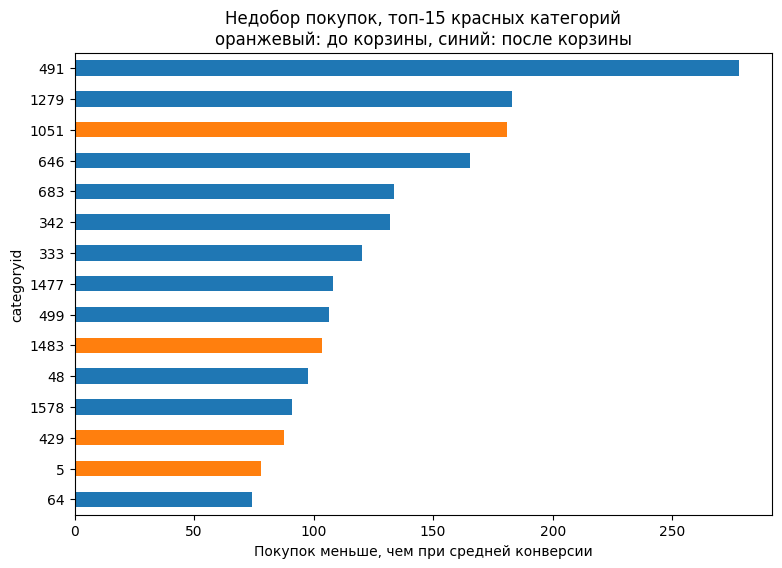

In [18]:
plot_df = red.sort_values("gap_tx")
colors = plot_df["weak_stage"].map({"до корзины": "tab:orange", "после корзины": "tab:blue"})

plot_df["gap_tx"].plot(kind="barh", figsize=(9, 6), color=colors.tolist())
plt.title("Недобор покупок, топ-15 красных категорий\nоранжевый: до корзины, синий: после корзины")
plt.xlabel("Покупок меньше, чем при средней конверсии")
plt.ylabel("categoryid")
plt.show()

## Выводы

- Среди посетителей с view в корзину добавляли 2,45%, покупали 0,8%. Это описательные доли, а не строгая воронка.
- Доля покупок зависит от времени суток: около 0,35-0,45% с 8 до 13 UTC и около 0,9% с 16 до 22.
  Это связь по времени, причину данные не показывают.
- Из 1086 категорий 160 покупают значимо хуже среднего по магазину, 176 лучше, 750 на уровне среднего.
- 80% просмотров дают 227 категорий из 1086, поэтому разбирать стоит в первую очередь крупные.
- Красные категории дают 44,9% просмотров, но только около 23% покупок (4965 из 21 982).
- Красные категории недобирают около 4900 покупок (22,3% от покупок с известной категорией), топ-15 около 1940 (8,8%).
  Это верхняя оценка при выходе на среднюю конверсию.
- В 11 из 15 категорий просадка после корзины, в 4 (1051, 1483, 429, 5) до корзины.
- Категории 1477, 499, 64 и 429 конвертятся в 4-9 раз хуже среднего, это самые острые случаи.
  Категории 491, 1279 и 1051 просто самые крупные по недобору.
- У топ-15 три самых активных посетителя дают не больше 1,6% просмотров, аномальных посетителей нет.

## Ограничения

- Нет session_id, доли среди посетителей описательные, а не строгая воронка.
- Категория берется последняя известная, а не на момент события.
- Категории нет у 9,5% просмотров, но только у 2,1% покупок, поэтому средняя конверсия по категориям может быть слегка завышена.
- Цена анонимизирована, поэтому низкая конверсия не значит проблему: это список для проверки, а не вердикт.
- Лог за ограниченный период и один магазин, сезонность не оценить.


In [19]:
cm.to_csv(data_dir / "category_scorecard.csv")